# Classification de textes – détecteur de spams

Nous commençons par charger tous les paquets et fonctions auxiliaires nécessaires.

In [1]:
# Load packages and helper functions
%run data_prep_tools.py
%run EDA_tools.py
%run modeling_tools.py

## Analyse exploratoire des données (EDA)

Dans le notebook consacré à la préparation des données, nous avons chargé un jeu de données contenant environ 6 000 e-mails étiquetés (spam et non-spam). Nous avons exploré le contenu textuel de ces e-mails et défini des procédures pour les nettoyer, extraire des caractéristiques numériques (comptage de « signatures » typiques des spams) ainsi que des caractéristiques textuelles. Nous avons également extrait des plongements (embeddings) du texte original des e-mails à l'aide d'un modèle de langage.

## Chargement des caractéristiques

Les trois espaces de caractéristiques peuvent être chargés via la fonction `load_feature_space()`.

Le paramètre `features` permet de spécifier les caractéristiques à charger. Les options disponibles sont :

* "num" : caractéristiques numériques
* "text" : (par défaut) caractéristiques textuelles
* "num_text" : combinaison de caractéristiques numériques et textuelles
* "embedding" : caractéristiques issues de plongements (embeddings)

Le paramètre `no_labels` permet de déterminer si les étiquettes doivent être exclues ou non :
- `True` pour exclure les étiquettes
- `False` (par défaut) pour inclure les étiquettes.

### Tâche

Explorer les différents espaces de caractéristiques.

Remarque : Pour faciliter l'analyse, nous travaillerons sur l'ensemble des données. En pratique, lors de la construction d'un modèle d'apprentissage supervisé — comme un filtre anti-spam —, on crée un ensemble d'entraînement et un ensemble de test. Vous pouvez explorer l'ensemble d'entraînement et utiliser les enseignements qui en découlent pour élaborer votre modèle. En revanche, l'ensemble de test ne doit pas être exploré, car il sert à évaluer les performances du modèle sur des données qu'il n'a jamais rencontrées.

### Aperçu du notebook

* Exploration des caractéristiques numériques
* Exploration des caractéristiques textuelles
* Exploration des plongements (embeddings)

In [2]:
labels = load_labels()

5832 labels loaded
Labels found: [1 0]


Commençons par examiner la répartition des étiquettes, c’est-à-dire le nombre d’e-mails qui sont des spams et ceux qui ne le sont pas.

<div class="alert alert-success">
<h3>Questions</h3>

__Q1.__ Que constatez-vous concernant la fréquence des e-mails indésirables (spams) et des e-mails légitimes ?

__Q2.__ Quel impact cela pourrait-il avoir sur l'entraînement du détecteur de spams ?

</div>

Samples per class (%):
non-spam    70.3
spam        29.7
Name: proportion, dtype: float64




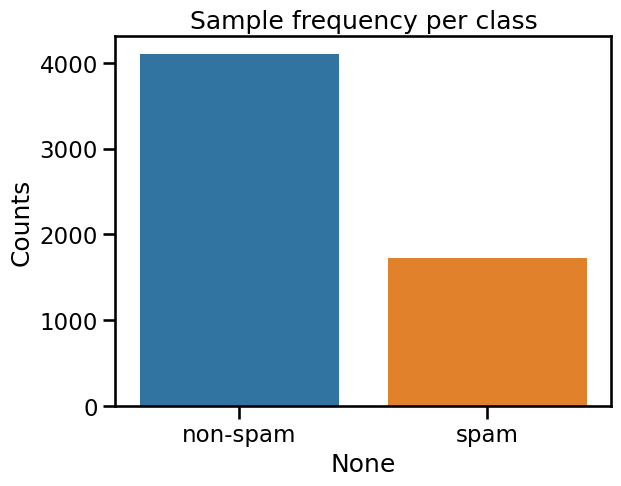

In [3]:
plot_class_frequency(labels)

#### Indiquez vos observations ici :

**Q1.**


**Q2.**



## Exploration des variables numériques

#### Aperçu des variables numériques
Les variables numériques sont les suivantes :
- "email_counts"
- "html_tag_counts"
- "url_counts"
- "twitter_username_counts"
- "hashtag_counts"
- "character_counts"
- "word_counts"
- "unique_word_counts"
- "punctuation_mark_counts"
- "uppercase_word_counts"
- "lowercase_word_counts"
- "digit_counts"
- "alphabetic_char_counts"

Notez que certaines variables ont fait l'objet d'une transformation logarithmique.

#### Chargement des variables numériques :

In [12]:
num_features_df = load_feature_space(features="num")

num_features_df

Numeric features loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 14 columns


,email_counts,html tag_counts,url_counts,Twitter username_counts,hashtag_counts,character_counts,word_counts,unique word_counts,punctuation mark_counts,uppercase word_counts,lowercase word_counts,digit_counts,alphabetic char_counts,spam_label
0,0,0,2,0,0,564,81,74,36,1,58,33,415,1
1,0,1,2,0,0,1239,161,123,222,12,89,17,840,1
2,0,2,3,0,0,808,123,96,83,4,70,69,534,1
3,0,0,3,0,0,1097,154,106,61,11,127,28,855,1
4,2,0,0,0,1,1732,309,207,109,45,211,42,1273,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5827,3,0,2,0,0,907,110,96,184,3,66,37,577,0
5828,0,0,2,0,0,241,31,31,26,3,19,2,183,0
5829,1,1,1,0,0,374,47,42,78,0,34,12,238,0
5830,2,3,3,0,0,1296,200,142,142,8,139,24,931,0


Examinons les distributions des variables numériques :
- sur l'ensemble du corpus, et
- en fonction de `spam_label`

afin de déterminer s'il existe des signes de différences entre les e-mails indésirables (spams) et les autres.

#### Corpus complet :

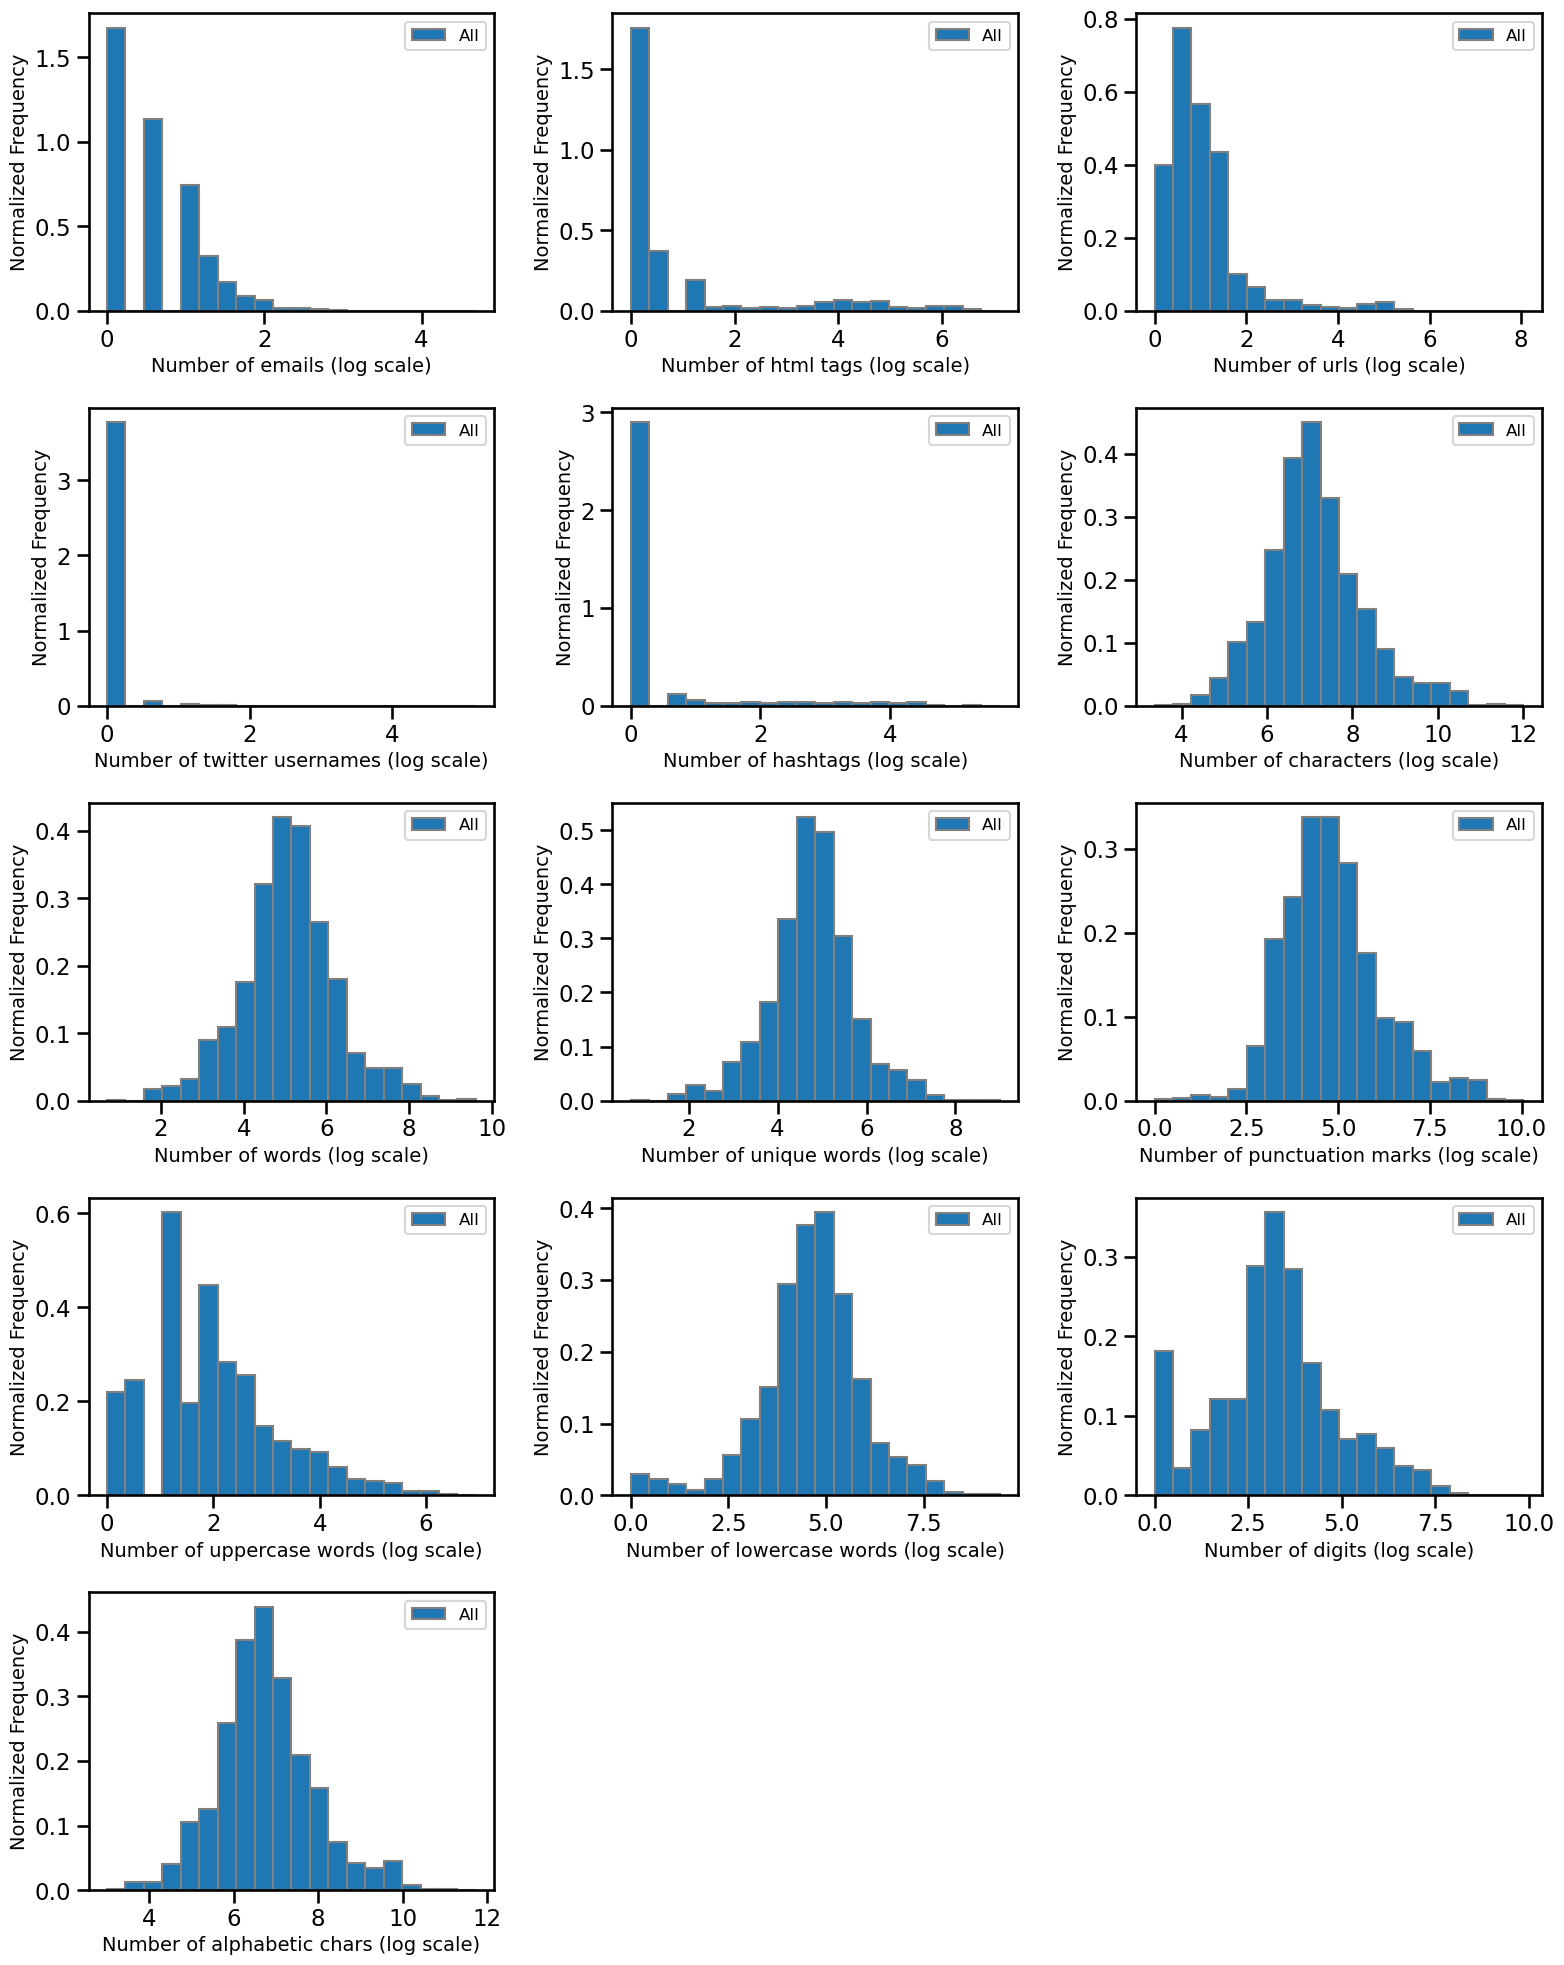

In [5]:
plot_numeric_features(num_features_df, with_labels=False)

#### Corpus divisé selon `spam_label` :

<div class="alert alert-success">
<h3>Questions</h3>

__Q1.__ Les e-mails indésirables (spams) et les e-mails légitimes diffèrent-ils, en moyenne, au regard de diverses caractéristiques numériques ?

* Les spams contiennent-ils davantage de balises HTML ?
* Les e-mails légitimes contiennent-ils davantage d'URL et d'adresses e-mail ?
* Les spams sont-ils plus longs que les e-mails légitimes ?
* ...

__Q2.__ Ces caractéristiques pourraient-elles s'avérer utiles pour distinguer les spams des e-mails légitimes ?
</div>

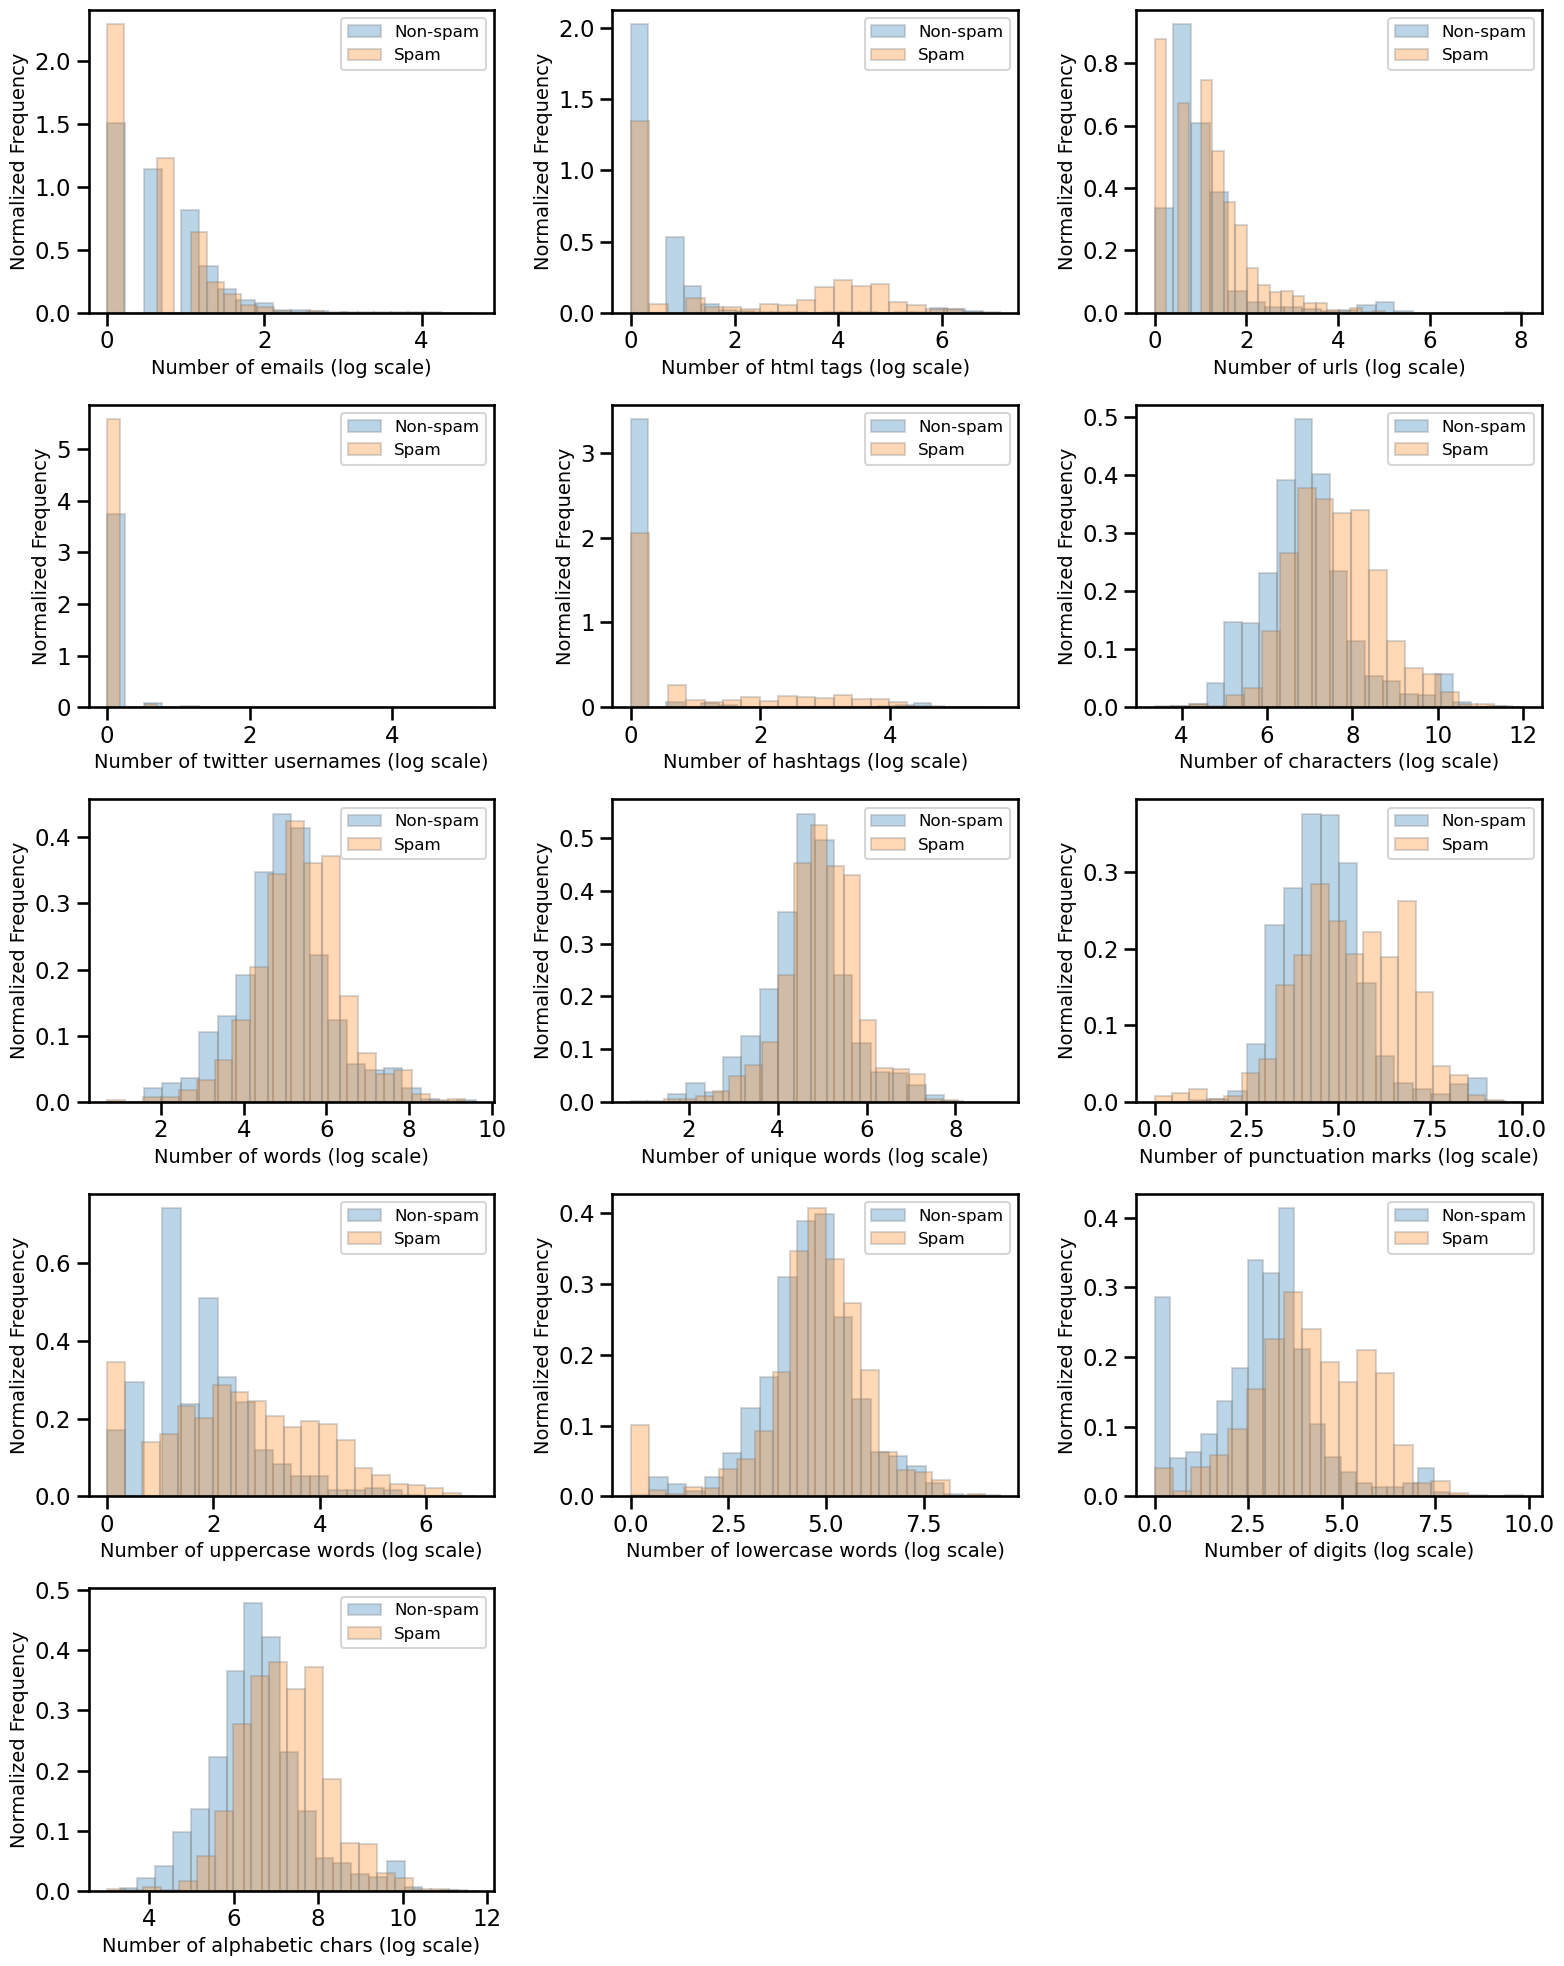

In [6]:
plot_numeric_features(num_features_df, with_labels=True)

#### Indiquez vos observations ici :

**Q1**





**Q2**






## Exploration des caractéristiques textuelles

Il est plus facile de travailler avec le texte nettoyé avant d'appliquer les vectoriseurs destinés à générer un espace de caractéristiques spécifique.

#### Chargement du texte nettoyé :

In [ ]:
df_source = load_source_data(verbose=False)
df_cleaned = clean_corpus(df_source, verbose=False)

Number of columns: 3
Columns names:
spam_label, text, text_cleaned



In [13]:
df_source

,spam_label,text
0,1,"Dear Homeowner, Interest Rates are at their lowest point in 40 years! We help you find the best rate for your situation by matching your needs with hundreds of lenders! Home Improvement, Refinance, Second Mortgage, Home Equity Loans, and More! Even with less than perfect credit! This service is 100% FREE to home owners and new home buyers without any obligation. Just fill out a quick, simple form and jump-start your future plans today! Visit http://61.145.116.186/user0201/index.asp?Afft=QM10 To unsubscribe, please visit: http://61.145.116.186/light/watch.asp"
1,1,"ATTENTION: This is a MUST for ALL Computer Users!!! *NEW-Special Package Deal!* Norton SystemWorks 2002 Software Suite -Professional Edition- Includes Six - Yes 6! - Feature-Packed Utilities ALL For 1 Special LOW Price! This Software Will: - Protect your computer from unwanted and hazardous viruses - Help secure your private & valuable information - Allow you to transfer files and send e-mails safely - Backup your ALL your data quick and easily - Improve your PC's performance w/superior integral diagnostics! 6 Feature-Packed Utilities...1 Great Price! A $300+ Combined Retail Value! YOURS for Only $29.99! <Includes FREE Shipping!> Don't fall prey to destructive viruses or hackers! Protect your computer and your valuable information! So don't delay...get your copy TODAY! http://euro.specialdiscounts4u.com/ ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++ This email has been screened and filtered by our in house """"OPT-OUT"""" system in compliance with state laws. If you wish to ""OPT-OUT"" from this mailing as well as the lists of thousands of other email providers please visit http://dvd.specialdiscounts4u.com/optoutd.html ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++"
2,1,"We dare you... Try to find a better annuity! =20 - 5.40% Guaranteed for 6 Years=0A= - 6 Year Surrender Charge=0A= - 5% Agent Commission up to age 80=09 Call today for more information! 800-888-7641 ext. 103 - or - Please fill out the form below for more information =20 Name: =09 E-mail: =20 Phone: =20 City: State: =20 =09 =20 PMG Financial Services *5.40% for deposits of $100,000 and up, 5.25% interest for deposits totalling $25,000-$99,999. =20 We don't want anyone to receive our mailings who does not wish to receive them. This is a professional communication sent to insurance professionals. To be removed from this mailing list, DO NOT REPLY to this message. Instead, go here: http://www.insuranceiq.com/optout <http://www.insuranceiq.com/optout/>=20 Legal Notice <http://www.insiq.com/legal.htm>=20"
3,1,"IMPORTANT INFORMATION: The new domain names are finally available to the general public at discount prices. Now you can register one of the exciting new .BIZ or .INFO domain names, as well as the original .COM and .NET names for just $14.95. These brand new domain extensions were recently approved by ICANN and have the same rights as the original .COM and .NET domain names. The biggest benefit is of-course that the .BIZ and .INFO domain names are currently more available. i.e. it will be much easier to register an attractive and easy-to-remember domain name for the same price. Visit: http://www.affordable-domains.com today for more info. Register your domain name today for just $14.95 at: http://www.affordable-domains.com/ Registration fees include full access to an easy-to-use control panel to manage your domain name in the future. Sincerely, Domain Administrator Affordable Domains To remove your email address from further promotional mailings from this company, click here: http://www.centralremovalservice.com/cgi-bin/domain-remove.cgi (g1-ss2)5592OxeR3-424uQKh2259kCdl5-189GEil31"
4,1,"This is the bottom line. If you can GIVE AWAY CD's for FREE to people (like 80-100 in one month) and then let ME talk to them FOR you - if you can GIVE AWAY free product samples - then YOU can earn $5,000 in the next 30 - 45 days. Think

In [14]:
df_cleaned

,spam_label,text,text_cleaned
0,1,"Dear Homeowner, Interest Rates are at their lowest point in 40 years! We help you find the best rate for your situation by matching your needs with hundreds of lenders! Home Improvement, Refinance, Second Mortgage, Home Equity Loans, and More! Even with less than perfect credit! This service is 100% FREE to home owners and new home buyers without any obligation. Just fill out a quick, simple form and jump-start your future plans today! Visit http://61.145.116.186/user0201/index.asp?Afft=QM10 To unsubscribe, please visit: http://61.145.116.186/light/watch.asp",dear homeowner rates lowest point years help best rate situation matching needs hundreds lenders home improvement refinance second mortgage home equity loans perfect credit service free home owners home buyers obligation just quick simple form jump start future plans today visit unsubscribe visit
1,1,"ATTENTION: This is a MUST for ALL Computer Users!!! *NEW-Special Package Deal!* Norton SystemWorks 2002 Software Suite -Professional Edition- Includes Six - Yes 6! - Feature-Packed Utilities ALL For 1 Special LOW Price! This Software Will: - Protect your computer from unwanted and hazardous viruses - Help secure your private & valuable information - Allow you to transfer files and send e-mails safely - Backup your ALL your data quick and easily - Improve your PC's performance w/superior integral diagnostics! 6 Feature-Packed Utilities...1 Great Price! A $300+ Combined Retail Value! YOURS for Only $29.99! <Includes FREE Shipping!> Don't fall prey to destructive viruses or hackers! Protect your computer and your valuable information! So don't delay...get your copy TODAY! http://euro.specialdiscounts4u.com/ ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++ This email has been screened and filtered by our in house """"OPT-OUT"""" system in compliance with state laws. If you wish to ""OPT-OUT"" from this mailing as well as the lists of thousands of other email providers please visit http://dvd.specialdiscounts4u.com/optoutd.html ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++",attention computer users special package deal norton systemworks software suite professional edition includes feature packed utilities special price software protect computer unwanted hazardous viruses help secure private valuable information allow transfer files send mails safely backup data quick easily improve performance superior integral diagnostics feature packed utilities great price combined retail value dont fall prey destructive viruses hackers protect computer valuable information dont delay copy today email screened filtered house compliance state laws wish mailing lists thousands email providers visit
2,1,"We dare you... Try to find a better annuity! =20 - 5.40% Guaranteed for 6 Years=0A= - 6 Year Surrender Charge=0A= - 5% Agent Commission up to age 80=09 Call today for more information! 800-888-7641 ext. 103 - or - Please fill out the form below for more information =20 Name: =09 E-mail: =20 Phone: =20 City: State: =20 =09 =20 PMG Financial Services *5.40% for deposits of $100,000 and up, 5.25% interest for deposits totalling $25,000-$99,999. =20 We don't want anyone to receive our mailings who does not wish to receive them. This is a professional communication sent to insurance professionals. To be removed from this mailing list, DO NOT REPLY to this message. Instead, go here: http://www.insuranceiq.com/optout <http://www.insuranceiq.com/optout/>=20 Legal Notice <http://www.insiq.com/legal.htm>=20",dare better annuity guaranteed years year surrender charge agent commission today information form information mail phone city state financial services deposits deposits totalling dont want receive mailings does wish receive professional communication sent insurance professionals removed mailing list reply message instead legal notice
3,1,"IMPORTANT INFORMATION: The new domain names are finally available to t

<div class="alert alert-success">


<h3>Questions</h3>

Analysons le texte nettoyé pour identifier les mots les plus fréquents. Vous pouvez modifier la valeur de `N` pour afficher un nombre plus ou moins élevé de mots.

__Q1.__ D'après votre expérience personnelle, quels mots, parmi ceux présentés ci-dessous, vous semblent les plus révélateurs de spams, et lesquels sont, au contraire, plus caractéristiques de messages légitimes (non-spams) ?

</div>

Top 30 words in all classes:
['list', 'email', 'free', 'just', 'time', 'mail', 'like', 'people', 'information', 'dont', 'make', 'click', 'mailing', 'business', 'message', 'linux', 'money', 'wrote', 'work', 'users', 'address', 'want', 'internet', 'know', 'send', 'software', 'need', 'home', 'spam', 'using']


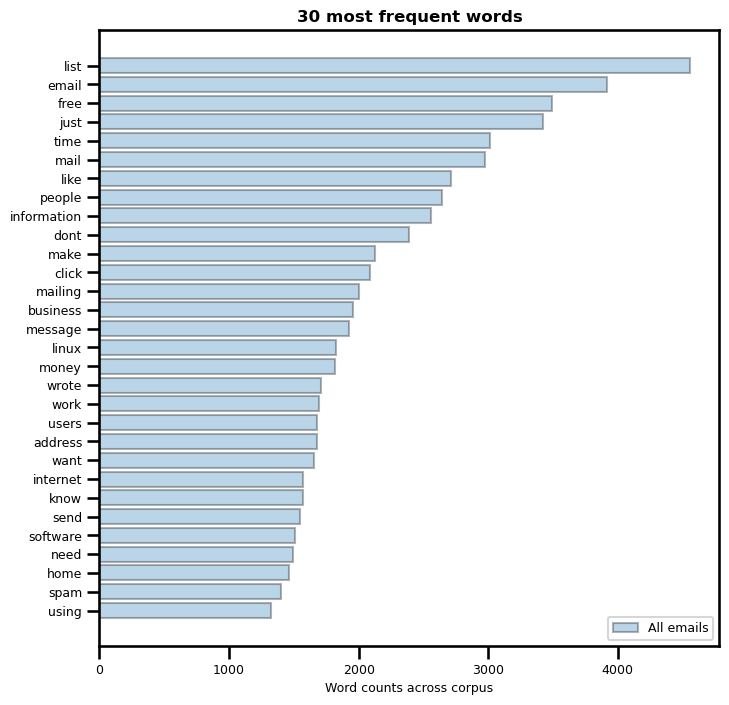

In [8]:
plot_most_common_words(df_cleaned, N=30, with_labels=False)

#### Indiquez vos observations ici :

**Q1**

<div class="alert alert-success">


<h3>Questions</h3>

Explorons maintenant les mots les plus fréquents dans chaque catégorie. Nous sélectionnons les `N` mots les plus courants de chaque catégorie et les regroupons dans un ensemble unique. Nous représentons ensuite graphiquement les **fréquences totales** (le nombre total d'occurrences) de tous ces mots pour les deux catégories. Le graphique contiendra donc plus de `N` mots. Les mots sont triés selon leur fréquence dans la catégorie « non-spam » (en bleu).

Vous pouvez modifier la valeur de `N` pour afficher un nombre plus ou moins élevé de mots.

__Q1.__ Selon vous, quels mots sont les plus révélateurs de spams, et lesquels sont les plus caractéristiques des messages qui ne sont pas des spams ?

__Q2.__ Le nombre total d'occurrences est-il représentatif de l'importance de chaque mot pour chacune des catégories ?


</div>

Top 15 words in class 0:
['list', 'just', 'like', 'time', 'linux', 'dont', 'wrote', 'users', 'people', 'mail', 'message', 'email', 'mailing', 'information', 'spam']
Top 15 words in class 1:
['email', 'free', 'click', 'business', 'money', 'mail', 'list', 'information', 'time', 'people', 'address', 'just', 'order', 'send', 'receive']


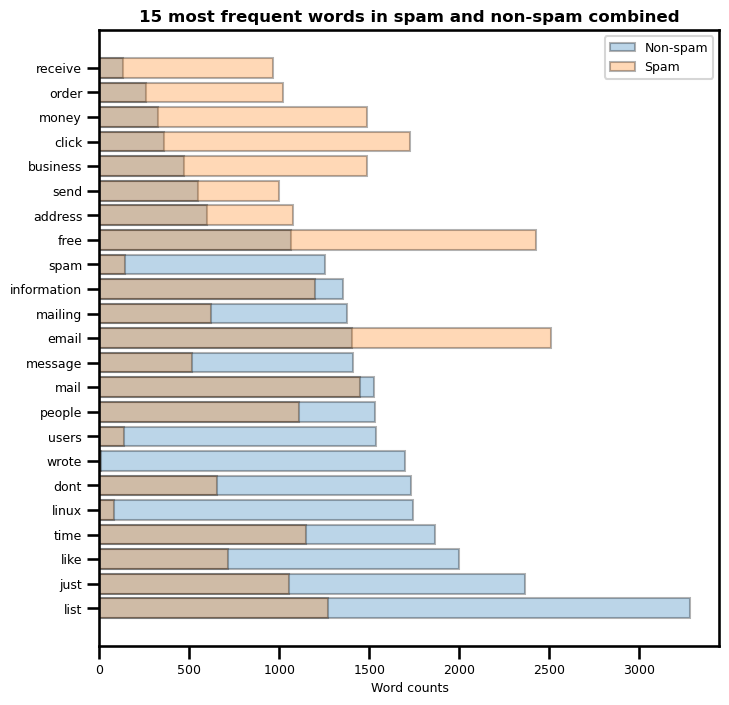

In [9]:
plot_most_common_tokens(df_cleaned, N=15)

#### Indiquez vos observations ici :

**Q1**




**Q2**





<div class="alert alert-success">


<h3>Questions</h3>


Répétons les décomptes ci-dessus, mais cette fois nous __tenons compte des différentes tailles de classe__. Nous utiliserons les fréquences relatives ajustées en ajustant nos décomptes à 1000 documents par classe.

__Q1.__ Selon vous, quels mots sont le plus représentatifs du spam et lesquels sont plus typiques du non-spam ?

__Q2.__ Qu'est-ce qui a changé en termes de mots qui semblent être de bons indicateurs pour l'une ou l'autre classe ?

__Q3.__ (Facultatif) En jouant un peu avec « N », pensez-vous que construire un modèle basé sur des fonctionnalités de texte peut donner de bons résultats ?

</div>

Top 15 words in class 0:
['list', 'just', 'like', 'time', 'linux', 'dont', 'wrote', 'users', 'people', 'mail', 'message', 'email', 'mailing', 'information', 'spam']
Top 15 words in class 1:
['email', 'free', 'click', 'business', 'money', 'mail', 'list', 'information', 'time', 'people', 'address', 'just', 'order', 'send', 'receive']


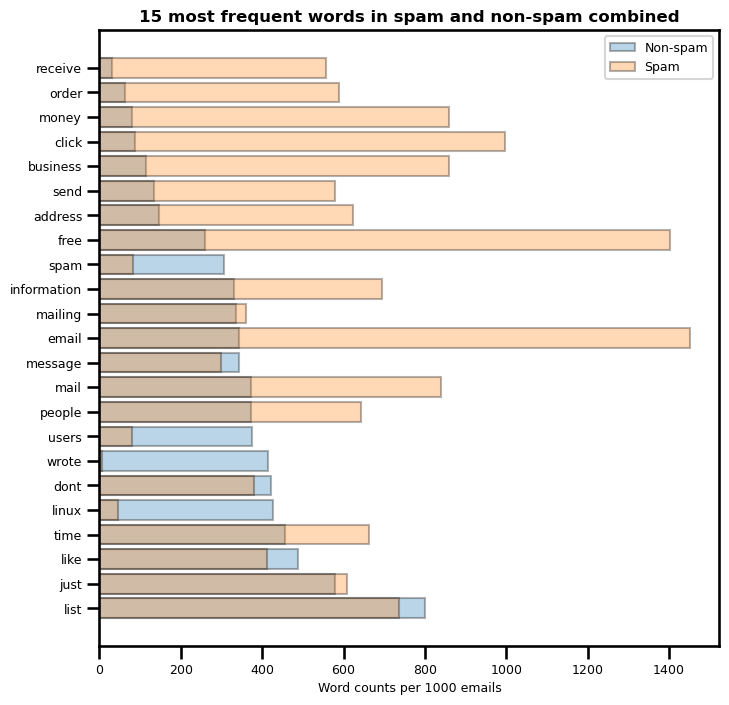

In [10]:
plot_most_common_tokens(df_cleaned, N=15, per_1000=True)

#### Indiquez vos observations ici :

**Q1**


**Q2**



**Q3**



## Exploration de l'espace latent (embedding space)


In [10]:
embeddings_df = load_feature_space(features="embedding")

Email embeddings loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 769 columns


In [11]:
embeddings_df

,0,1,2,3,4,5,6,7,8,9,...,759,760,761,762,763,764,765,766,767,spam_label
0,-0.012375,-0.018982,-0.015450,0.017502,0.035553,-0.000460,0.033569,-0.013542,-0.019363,0.043488,...,0.044556,0.022995,0.029587,0.011559,-0.008163,-0.017242,-0.009918,-0.034943,-0.039642,1
1,-0.000592,-0.036469,-0.025589,0.017731,0.031860,-0.045624,0.051300,0.025131,-0.002958,0.040955,...,0.036346,0.004608,0.048950,-0.039093,0.036530,-0.025406,-0.004711,-0.006947,-0.029343,1
2,-0.015625,-0.032959,-0.017868,0.030594,0.015976,-0.012680,0.016617,-0.008224,-0.026474,0.016998,...,0.034149,-0.034698,0.015778,-0.043640,0.021210,0.010658,-0.027863,-0.005669,-0.029877,1
3,0.033661,-0.025314,-0.006813,0.028290,0.037445,-0.038208,0.043976,0.011978,-0.022675,0.003136,...,0.023895,-0.004593,0.033997,-0.013504,0.049042,-0.014023,0.014267,-0.017975,-0.014648,1
4,0.001591,-0.035309,0.008095,0.017120,0.026047,-0.008377,0.017639,-0.000340,-0.005836,0.022491,...,0.022400,-0.018723,0.050751,-0.040710,0.009834,-0.022888,-0.026047,-0.012299,-0.013359,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5827,0.008011,-0.020691,-0.001282,0.034973,0.045685,-0.007088,0.032745,0.038391,-0.036285,0.031403,...,0.044678,-0.028458,0.044220,-0.043732,0.032654,0.021362,0.014870,-0.049103,0.005161,0
5828,0.046356,-0.023026,-0.032135,-0.005852,0.044250,-0.002863,0.056335,0.051361,-0.026260,0.031921,...,0.005466,0.026779,0.005558,-0.039459,0.036957,-0.019485,0.021637,-0.045746,-0.044373,0
5829,0.006779,0.013428,0.032379,0.049042,0.021103,-0.000590,0.015205,0.057068,-0.012962,0.025085,...,0.043335,-0.004395,-0.002819,-0.061951,0.013863,0.025192,0.018921,0.000262,-0.021347,0
5830,0.022568,-0.012177,0.038483,0.040710,0.026093,-0.009605,0.034698,0.021896,-0.017410,-0.001927,...,0.039307,-0.006214,0.007465,-0.042664,0.035828,-0.008530,0.040314,-0.002905,0.000853,0


### ACP

Les espaces de très grande dimension peuvent poser problème aux algorithmes d'apprentissage automatique, car ils peuvent contenir des informations redondantes ou du bruit. Nous cherchons donc à déterminer s'il est possible de réduire la dimensionnalité de notre jeu de données. En d'autres termes, nous souhaitons compresser les données pour ne conserver que les informations les plus pertinentes. Cela permet d'économiser de l'espace, d'accélérer les calculs et de réduire le bruit.

Une méthode courante en apprentissage automatique est l'**analyse en composantes principales (ACP)**, qui identifie de manière itérative les directions au sein des données présentant la variance la plus élevée. Elle permet ensuite de réduire l'espace en projetant les données uniquement sur les composantes les plus pertinentes.

**Remarque** : L'ACP est une méthode d'apprentissage automatique _non supervisé_, car elle n'utilise aucune information concernant notre cible (ici, les étiquettes « spam »).

<div class="alert alert-success">


<h3>Questions</h3>

Nous réalisons ci-dessous une analyse en composantes principales (ACP) sur l'espace des plongements (*embedding space*). Nous déterminons le nombre de composantes nécessaires pour expliquer un certain niveau de variance globale, puis nous visualisons les résultats à l'aide d'un graphique des valeurs propres (*scree plot*) et d'un tableau.

Nous représenterons également les deux premières composantes sur un graphique de dispersion (*scatter plot*).

__Q1.__ Quelle proportion de la variance est expliquée par les deux premières composantes principales ?

__Q2.__ Dans quelle mesure l'espace des caractéristiques pourrait-il être réduit si l'on souhaitait conserver 90 % de la variance ?

__Q3.__ En examinant le graphique de dispersion, quelles conclusions pouvez-vous tirer des résultats de l'ACP concernant la séparation des classes ?


</div>

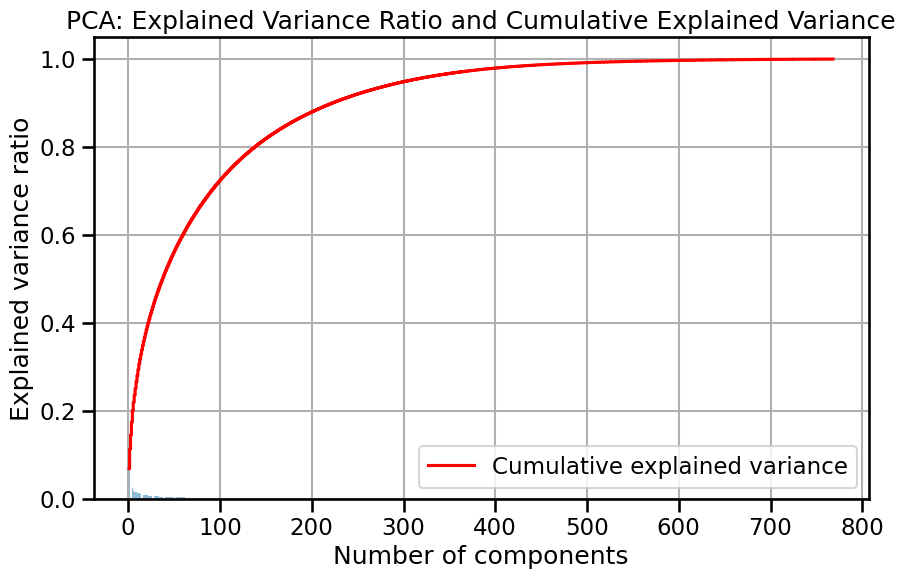

Number of components for 10% explained variance: 2
Number of components for 20% explained variance: 5
Number of components for 30% explained variance: 12
Number of components for 40% explained variance: 22
Number of components for 50% explained variance: 38
Number of components for 60% explained variance: 60
Number of components for 70% explained variance: 91
Number of components for 80% explained variance: 138
Number of components for 90% explained variance: 223
Number of components for 100% explained variance: 1


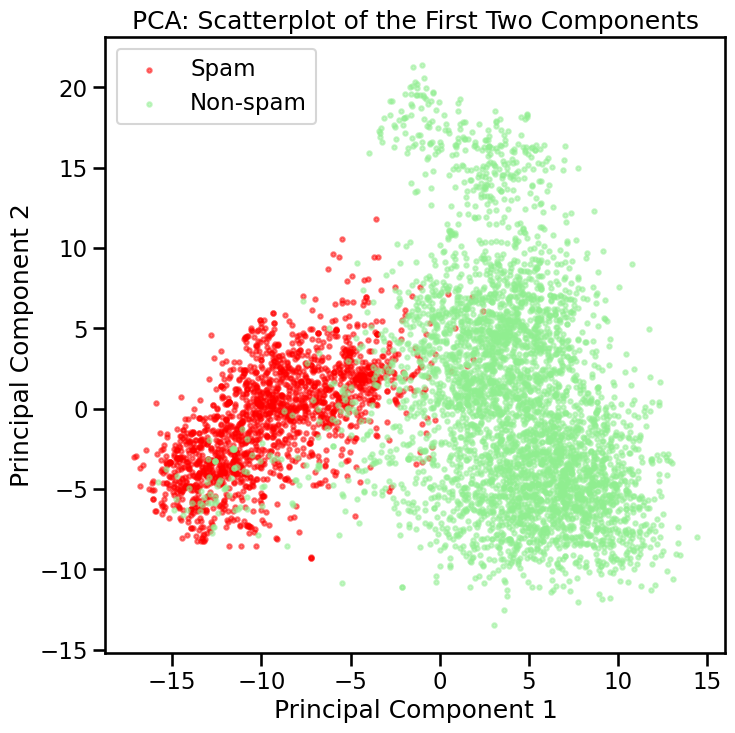

In [12]:
embeddings_pca_df = run_pca(embeddings_df, with_labels=True)

#### Présentez vos observations ici :

**Q1**



**Q2**



**Q3**



